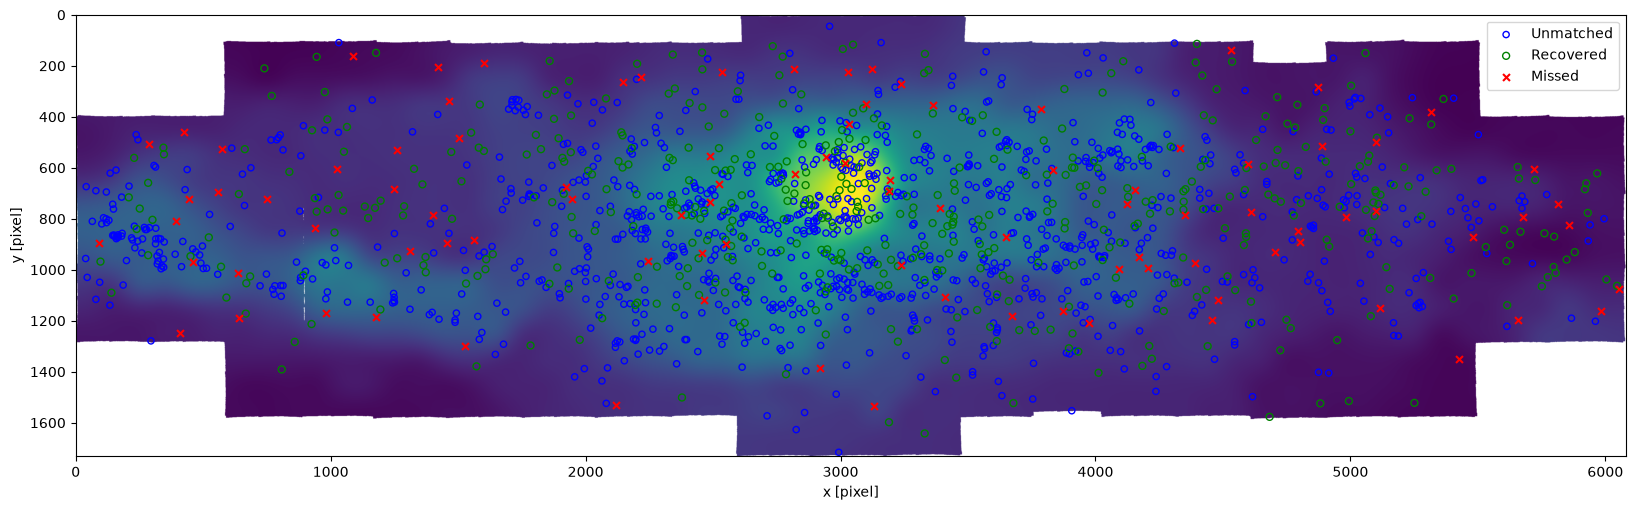

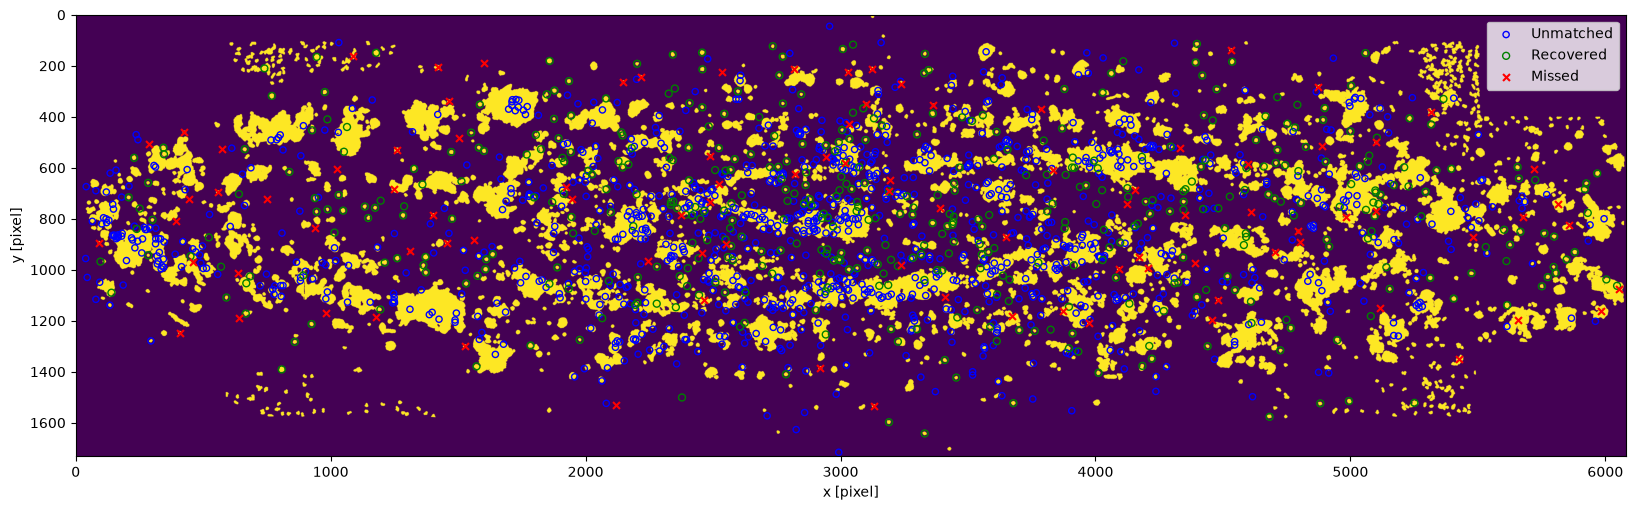

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from astropy.io import fits

FITS_PATH = "/Users/golta/Neb_det/data/NGC253_4channel.fits"
ORIGINAL_FITS_PATH = "/Users/golta/Neb_det/data/ADP.2025-07-06T07_52_11.876.fits"

CATALOG_PATH = Path("/Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v4.3/diagnostic_source_measurements_v4.2.csv")
BACKGROUND_NPZ = "/Users/golta/Neb_det/output/PN_detection/BKG/NGC253_background_and_errors.npz"
USED_LINES = ["Hbeta", "OIII5007", "Halpha", "NII6584"]
BACKGROUND_KEYS = {
    "Hbeta": "hb_background",
    "OIII5007": "oiii_background",
    "Halpha": "ha_background",
    "NII6584": "nii_background",
}

ERROR_KEYS = {
    "Hbeta": "hb_error",
    "OIII5007": "oiii_error",
    "Halpha": "ha_error",
    "NII6584": "nii_error",
}

with np.load(BACKGROUND_NPZ) as background_data:
    full_background_maps = np.stack(
        [
            np.array(background_data[BACKGROUND_KEYS[line_name]], dtype=np.float32, copy=True)
            for line_name in USED_LINES
        ],
        axis=0,
    )

    full_error_maps = np.stack(
        [
            np.array(background_data[ERROR_KEYS[line_name]], dtype=np.float32, copy=True)
            for line_name in USED_LINES
        ],
        axis=0,
    )

    common_valid = np.array(
        background_data["common_valid"],
        dtype=bool,
        copy=True,
    )

    source_mask = np.array(
        background_data["source_mask"],
        dtype=bool,
        copy=True,
    )

diagnostic_table = pd.read_csv(CATALOG_PATH)
unmatched_nonedge = diagnostic_table[
    (diagnostic_table["population"] == "Unmatched candidate") & (~diagnostic_table["edge_object"])
]
recovered = diagnostic_table[diagnostic_table["population"] == "Recovered catalogue PN"]
missed = diagnostic_table[diagnostic_table["population"] == "Missed catalogue PN"]

plt.figure(figsize=(20, 20))
plt.imshow(full_background_maps[1])
plt.scatter(unmatched_nonedge["center_x"], unmatched_nonedge["center_y"], s=20, label="Unmatched", facecolors="None", edgecolors="blue")
plt.scatter(recovered["center_x"], recovered["center_y"], s=25, marker="o", edgecolors="g", facecolors="None", label="Recovered")
plt.scatter(missed["center_x"], missed["center_y"], s=25, marker="x", label="Missed", color="r")
plt.xlabel("x [pixel]")
plt.ylabel("y [pixel]")
plt.legend(loc="best")
plt.show()

plt.figure(figsize=(20, 20))
plt.imshow(source_mask)
plt.scatter(unmatched_nonedge["center_x"], unmatched_nonedge["center_y"], s=20, label="Unmatched", facecolors="None", edgecolors="blue")
plt.scatter(recovered["center_x"], recovered["center_y"], s=25, marker="o", edgecolors="g", facecolors="None", label="Recovered")
plt.scatter(missed["center_x"], missed["center_y"], s=25, marker="x", label="Missed", color="r")
plt.xlabel("x [pixel]")
plt.ylabel("y [pixel]")
plt.legend(loc="best")
plt.show()